In [33]:
import os
import pandas as pd
import numpy as np
import matplotlib as plt
import networkx as nx
import mip

BUILDING_NAME = 'Edificio1.csv'

ASCENDING_SPEED = 1.0
DESCENDING_SPEED = 2.0
HORIZONTAL_SPEED = 1.5

ASCENDING_ENERGY= 50
DESCENDING_ENERGY= 5
HORIZONTAL_ENERGY = 10
    
X_BASE_RANGE = range(-8, 6) if 'Edificio1.csv' == BUILDING_NAME else range(-10, 11)
Y_BASE_RANGE = range(-17, -14) if 'Edificio1.csv' == BUILDING_NAME else range(-31, -29)
Z_BASE = 0

BATTERY_CAPACITY = 3600 if 'Edificio1.csv' == BUILDING_NAME else 21600 #1 Wh is 3600 J

Y_ENTRY_POINT = -12.5 if 'Edificio1.csv' == BUILDING_NAME else -20.0

# Reading CSV and creating pairs


In [34]:
#loading building csv data

nodes = pd.read_csv(BUILDING_NAME)

# Creating Bases and entry points

In [35]:
# Adding is_base and is_entry_point columns

nodes['is_base'] = False

nodes['is_entry_point'] = nodes['y']<=Y_ENTRY_POINT


# Creating new rows for base points
bases = []
for x in X_BASE_RANGE:
    for y in Y_BASE_RANGE:
        bases.append({'x': x, 'y': y, 'z': Z_BASE, 'is_base': True, 'is_entry_point': False})

# Appending base rows to the building dataframe
building = pd.concat([nodes, pd.DataFrame(bases)], ignore_index=True)

building.to_csv('building.csv', index=False)


# Merging nodes to create pairs

In [36]:
#setting node numbering from 1 to n
building.index += 1 

#generating all possible pairs of points (edges)
nodes_pairs = building.rename_axis('source_node').reset_index().merge(building.rename_axis('target_node').reset_index(), how='cross')

#removing self-self pairs
nodes_pairs = nodes_pairs[nodes_pairs['source_node'] != nodes_pairs['target_node']] #keeping only pairs with different points

In [37]:
first_point_cols= ['x_x','y_x','z_x']
second_point_cols=['x_y','y_y','z_y']
diff_cols= ['dx','dy','dz']

# Computing distances 

In [38]:
#function to determine if two points are connected based on distance and coordinate deltas

def process_connections(dataframe):
    #distances and deltas on coordinates
    dataframe[diff_cols] = (dataframe[second_point_cols].values - dataframe[first_point_cols].values)
    dataframe['euclidean_distance'] = np.sqrt((dataframe[diff_cols]**2).sum(axis=1)) #axis=1 sum on columns 
    
    
    # conditions near and tunnel
    condition_near = (dataframe['euclidean_distance'] <= 4.0)
    
    
    condition_tunnel = (
        ((dataframe['dx'].abs() <= 0.5) & (dataframe['dy'].abs() <= 0.5)) | 
        ((dataframe['dy'].abs() <= 0.5) & (dataframe['dz'].abs() <= 0.5)) | 
        ((dataframe['dx'].abs() <= 0.5) & (dataframe['dz'].abs() <= 0.5))
    )

    condition_tunnel_and_not_far = (dataframe['euclidean_distance'] <= 11.0) & condition_tunnel
    
    #if the arc is from base to entry point or viceversa
    condition_base_to_entry_point = (
        ((dataframe['is_base_x']) & (dataframe['is_entry_point_y'])) |
        ((dataframe['is_base_y']) & (dataframe['is_entry_point_x']))
    )

    #if both points are base points
    condition_base_to_base = (
        (dataframe['is_base_x']) & (dataframe['is_base_y'])
    )

    # final connection condition
    dataframe["are_connected"] = (condition_near & ~condition_base_to_base) | (condition_tunnel_and_not_far & ~condition_base_to_base) | condition_base_to_entry_point
    return dataframe



In [39]:
nodes_pairs = process_connections(nodes_pairs)

nodes_pairs.to_csv('pairs.csv', index=False)

nodes_pairs.head()

,source_node,x_x,y_x,z_x,is_base_x,is_entry_point_x,target_node,x_y,y_y,z_y,is_base_y,is_entry_point_y,dx,dy,dz,euclidean_distance,are_connected
1,1,2.5,3.25,0.0,False,False,2,-6.0,3.25,0.0,False,False,-8.5,0.0,0.0,8.500000,True
2,1,2.5,3.25,0.0,False,False,3,-6.0,11.75,0.0,False,False,-8.5,8.5,0.0,12.020815,False
3,1,2.5,3.25,0.0,False,False,4,2.5,11.75,0.0,False,False,0.0,8.5,0.0,8.500000,True
4,1,2.5,3.25,0.0,False,False,5,2.5,3.25,11.0,False,False,0.0,0.0,11.0,11.000000,True
5,1,2.5,3.25,0.0,False,False,6,-6.0,3.25,11.0,False,False,-8.5,0.0,11.0,13.901439,False


In [40]:
#computing vertical distances on z and distances on horizontal plane x,y
nodes_pairs["d_horizontal"] = np.sqrt(nodes_pairs['dx']**2 + nodes_pairs['dy']**2)
nodes_pairs["d_vertical"] = nodes_pairs['dz']

#dropping columns that are not useful anymore
nodes_pairs.drop(columns=['dx','dy','dz'], inplace=True)
nodes_pairs.drop(columns=['x_x','y_x','z_x','x_y','y_y','z_y'], inplace=True)

#keeping only connected pairs
nodes_pairs = nodes_pairs[nodes_pairs['are_connected']==True]
nodes_pairs.drop(columns=['are_connected'], inplace=True)

nodes_pairs.head(5)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,euclidean_distance,d_horizontal,d_vertical
1,1,False,False,2,False,False,8.500000,8.500000,0.0
3,1,False,False,4,False,False,8.500000,8.500000,0.0
4,1,False,False,5,False,False,11.000000,0.000000,11.0
18,1,False,False,19,False,False,4.007805,4.007805,0.0
19,1,False,False,20,False,False,1.030776,1.030776,0.0


# Function for time travel

In [41]:
#finding rows corresponding to different movement types 

d_horizontal = nodes_pairs['d_horizontal']
d_vertical = nodes_pairs['d_vertical']
rows_horizontal = (d_vertical == 0)
rows_ascending = (d_horizontal == 0) & (d_vertical > 0)
rows_descending = (d_horizontal == 0) & (d_vertical < 0)
rows_oblique_ascending = (d_horizontal != 0) & (d_vertical > 0)
rows_oblique_descending = (d_horizontal != 0) & (d_vertical < 0)

In [42]:
#function for time travel based on movement types and speeds

def compute_time_travel(dataframe):
    dataframe.loc[rows_horizontal, 'time_travel'] = dataframe.loc[rows_horizontal, 'd_horizontal'] / HORIZONTAL_SPEED

    dataframe.loc[rows_ascending, 'time_travel'] = dataframe.loc[rows_ascending, 'd_vertical'] / ASCENDING_SPEED
    dataframe.loc[rows_descending, 'time_travel'] = -dataframe.loc[rows_descending, 'd_vertical'] / DESCENDING_SPEED

    dataframe.loc[rows_oblique_ascending, 'time_travel'] = np.maximum(dataframe.loc[rows_oblique_ascending, 'd_horizontal'] / HORIZONTAL_SPEED,
                                                                     dataframe.loc[rows_oblique_ascending, 'd_vertical'] / ASCENDING_SPEED)
    
    dataframe.loc[rows_oblique_descending, 'time_travel'] = np.maximum(dataframe.loc[rows_oblique_descending, 'd_horizontal'] / HORIZONTAL_SPEED,
                                                                     -dataframe.loc[rows_oblique_descending, 'd_vertical'] / DESCENDING_SPEED)
    return dataframe

# Function for energy consumption


In [43]:
#function for energy cost based on movement types and energy consumption rates

def compute_energy_cost(dataframe):
    dataframe.loc[rows_horizontal, 'energy_consumption'] = dataframe.loc[rows_horizontal, 'd_horizontal'] * HORIZONTAL_ENERGY

    dataframe.loc[rows_ascending, 'energy_consumption'] = dataframe.loc[rows_ascending, 'd_vertical'] * ASCENDING_ENERGY
    dataframe.loc[rows_descending, 'energy_consumption'] = -dataframe.loc[rows_descending, 'd_vertical'] * DESCENDING_ENERGY

    dataframe.loc[rows_oblique_ascending, 'energy_consumption'] = (dataframe.loc[rows_oblique_ascending, 'd_horizontal'] * HORIZONTAL_ENERGY +
                                                                  dataframe.loc[rows_oblique_ascending, 'd_vertical'] * ASCENDING_ENERGY)
    
    dataframe.loc[rows_oblique_descending, 'energy_consumption'] = (dataframe.loc[rows_oblique_descending, 'd_horizontal'] * HORIZONTAL_ENERGY +
                                                                  -dataframe.loc[rows_oblique_descending, 'd_vertical'] * DESCENDING_ENERGY)
    return dataframe

# Actually computing energy and time costs for arcs

In [44]:
#computing time travel and energy cost for each pair (edges)

nodes_pairs = compute_time_travel(nodes_pairs)

nodes_pairs = compute_energy_cost(nodes_pairs)

nodes_pairs.drop(columns=['d_horizontal','d_vertical', 'euclidean_distance'], inplace=True)

nodes_pairs.head(10)


,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,time_travel,energy_consumption
1,1,False,False,2,False,False,5.666667,85.000000
3,1,False,False,4,False,False,5.666667,85.000000
4,1,False,False,5,False,False,11.000000,550.000000
18,1,False,False,19,False,False,2.671870,40.078049
19,1,False,False,20,False,False,0.687184,10.307764
106,2,False,False,1,False,False,5.666667,85.000000
108,2,False,False,3,False,False,5.666667,85.000000
111,2,False,False,6,False,False,11.000000,550.000000
124,2,False,False,19,False,False,3.004626,45.069391
125,2,False,False,20,False,False,5.002777,75.041655


# Creating Graph with Networkx


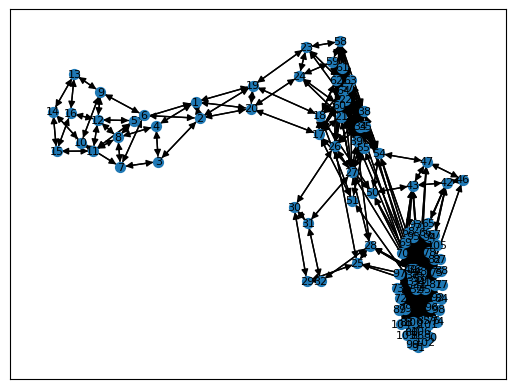

In [45]:
#creating directed graph G from the dataframe of edges with costs

G = nx.from_pandas_edgelist(
    nodes_pairs,                                     # dataframe containing edges
    source='source_node',                            # indicating the start of the edge
    target='target_node',                            # indicating the end of the edge
    edge_attr=['time_travel', 'energy_consumption'], # edge costs
    create_using=nx.DiGraph()                        # creating an oriented graph
)

nx.draw_networkx(G, node_size=50, font_size=8)

In [46]:
#For example, accessing edge attributes
    
energy_consume = G[1][2]['energy_consumption'] #energy consumption from node 1 to node 2
time = G[1][2]['time_travel']

print(f"Energy consumption from node 1 to node 2: {energy_consume} J")
print(f"Time travel from node 1 to node 2: {time} s")

Energy consumption from node 1 to node 2: 85.0 J
Time travel from node 1 to node 2: 5.666666666666667 s


In [47]:
# iterating over all the list of tuples of edges, data=True to get edge attributes.
for source, target, costs in G.edges(data=True): 
    print(f"Arco da {source} a {target}:")
    print(f"    Tempo: {costs['time_travel']}")
    print(f"    Energia: {costs['energy_consumption']}")

Arco da 1 a 2:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 1 a 4:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 1 a 5:
    Tempo: 11.0
    Energia: 550.0
Arco da 1 a 19:
    Tempo: 2.6718699236469
    Energia: 40.078048854703496
Arco da 1 a 20:
    Tempo: 0.6871842709362768
    Energia: 10.307764064044152
Arco da 2 a 1:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 2 a 3:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 2 a 6:
    Tempo: 11.0
    Energia: 550.0
Arco da 2 a 19:
    Tempo: 3.0046260628866577
    Energia: 45.069390943299865
Arco da 2 a 20:
    Tempo: 5.002777006601211
    Energia: 75.04165509901817
Arco da 4 a 1:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 4 a 3:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 4 a 8:
    Tempo: 11.0
    Energia: 550.0
Arco da 5 a 1:
    Tempo: 5.5
    Energia: 55.0
Arco da 5 a 6:
    Tempo: 5.666666666666667
    Energia: 85.0
Arco da 5 a 8:
    Tempo: 5.666666666666667
    Energia: 85.0

In [48]:
#IL DATAFRAME BASES CONTIENE TUTTE LE BASI
# I NODI(SENZA LE BASI) SI TROVANO NEL NODES DATAFRAME
# TUTTI I NODI SONO IN G.nodes
# IL NODES_PAIRS CONTIENE GLI ARCHI TRA TUTTI I NODI
#IL SET H È UN INSIEME DI NUMERI DA 0 A UN NUMERO k CHE VA STIMATO BENE, UPPER BOUND = NUMERO DI NODI

m=mip.Model(solver_name=mip.CBC)

#SETS AND PARAMETERS
#---------------------------------------------------------------
N=G.nodes #set of nodes

bases_x = nodes_pairs[nodes_pairs['is_base_x']==True]['source_node'].unique()
bases_y = nodes_pairs[nodes_pairs['is_base_y']==True]['target_node'].unique()
B = list(bases_x.tolist() + bases_y.tolist()) #set of base nodes
S = list(N - B) #set of service nodes

print(f"set N = {N}")
print(f"set B = {B}")
print(f"set S = {S}")

H = list(range(1, len(N))) #set of drone tours
print(f"set H = {H}")

A=G.edges  # set of arcs
print(f"set A = {A}")

_, _, costs = G.edges(data=True)  # costs of arcs
t=costs['time_travel']  # time travel cost
e=costs['energy_consumption']  # energy consumption cost
C=BATTERY_CAPACITY  # battery capacity
M=10**3  # big M constant ??

#VARIABLES
#---------------------------------------------------------------
x={(i,j,h): m.add_var(var_type=mip.BINARY) for i,j in A for h in H}  # binary variable indicating if arc (i,j) is used in tour h
b={i: m.add_var(var_type=mip.BINARY) for i in B}  # binary variable indicating if base i is used



set N = [1, 2, 4, 5, 19, 20, 3, 6, 7, 8, 11, 12, 9, 10, 13, 14, 15, 16, 17, 18, 21, 50, 51, 60, 63, 64, 22, 57, 61, 62, 23, 24, 27, 34, 35, 39, 54, 55, 59, 26, 38, 58, 25, 28, 29, 33, 37, 30, 31, 40, 32, 36, 56, 45, 48, 53, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 41, 42, 44, 49, 43, 46, 47, 52]
set B = [65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106]
set S = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53

ValueError: too many values to unpack (expected 3)